In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import scipy 
from numba import njit, prange
import h5py
from scipy.integrate import quad
from iminuit import Minuit
import tqdm
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad
from scipy.interpolate import CubicSpline

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

In [3]:
from Functions import compute_for_constant_diffusion

In [4]:
def compute_for_sigmoidal_constantD(r_target, rf, rn, A, b, D0, ndim=3, N=4000):
    """
    Returns a callable F(r) evaluating
      F(r) = ∫_{r_target}^{r} (1/phi(y)) * [ ∫_{y}^{r_n} phi(z)/D(z) dz ] dy
    where phi solves phi'(r) = (mu(r)/D(r))*phi(r), phi(r_target)=1.
    The diffusion coefficient D is constant (D0), and the drift mu(r) is derived from a sigmoidal potential U(r) = A * sigmoid(b*(r-rf)).
    """

    # definitions (vectorized-friendly)
    def sigmoid(x): 
        return 1.0 / (1.0 + np.exp(-x))

    def sigmoid_derivative(x):
        e = np.exp(-x) 
        return e / (1.0 + e)**2

    def dU(rr):
        return A * sigmoid_derivative(b * (rr - rf)) * b

    def drift(rr):
        return (ndim - 1) * D0 / rr - D0 * dU(rr)

    # grid
    r_eval = np.linspace(r_target, rn, N)

    # ODE: phi' = (mu/D) * phi
    def rhs(x, phi):
        return (drift(x) / D0) * phi

    # solve_ivp(func, t_span, rhs(t_span[0]), t_eval=..., rtol=..., atol=...)
    # Instead of time, we use the spatial variable r here
    sol = solve_ivp(rhs, (r_target, rn), y0=[1.0], t_eval=r_eval, rtol=1e-9, atol=1e-12)
    if not sol.success:
        raise RuntimeError("phi ODE failed: " + sol.message)
    phi = sol.y[0]

    # inner integral I(y) = ∫_{y}^{r_n} phi(z)/D(z) dz (right-to-left cumulative)
    inner_integrand = phi / D0
    reverse_inner_integral = cumulative_trapezoid(inner_integrand[::-1], r_eval[::-1], initial=0.0)  # ∫_{r_n}^{x} g
    inner_integral = -reverse_inner_integral[::-1]                                              # ∫_{x}^{r_n} g

    # outer integral F(r) = ∫_{r_target}^{r} [I(y)/phi(y)] dy
    outer_integrand = inner_integral / phi
    outer_integral = cumulative_trapezoid(outer_integrand, r_eval, initial=0.0)

    # spline for fast evaluation
    outer_spline = CubicSpline(r_eval, outer_integral, bc_type="natural", extrapolate=False)

    def outer_integral_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, r_n].")
        return outer_spline(r)

    return outer_integral_func, {"r_grid": r_eval, "phi": phi, "inner_integral": inner_integral, "outer_integrand": outer_integrand, "outer_integral": outer_integral}


# Constant A - Test as function of D

## 1D 

In [21]:
# For constant diffusion compare the two different potential energy landscapes - quadratic vs sigmoidal - and see how the MFPT changes.

# Common parameters
rn = 0.5 
r_target = 0.01
A = 5.0 

# Sigmoidal paramters 
rf = 0.1
b = 1000.0 

# Quadratic parameters 
hi, lo = A/4, -A/4
alpha_arr = np.linspace(lo, hi, 250)

In [22]:
N_D = 20
D_arr = np.linspace(0.05, 1.0, N_D)

mfpt_sigmoid_constD = np.zeros(N_D)
mfpt_quadratic_constD = np.zeros((N_D, len(alpha_arr)))

for i, D_i in enumerate(D_arr):
    print(f"Computing for D={D_i:.3f} ({i+1}/{N_D})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A, b, D_i, ndim=1)
    mfpt_sigmoid_constD[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A, D_i, alpha, ndim=1)
        mfpt_quadratic_constD[i, j] = quadratic_data["outer_integral"][-1]

Computing for D=0.050 (1/20)
Computing for D=0.100 (2/20)
Computing for D=0.150 (3/20)
Computing for D=0.200 (4/20)
Computing for D=0.250 (5/20)
Computing for D=0.300 (6/20)
Computing for D=0.350 (7/20)
Computing for D=0.400 (8/20)
Computing for D=0.450 (9/20)
Computing for D=0.500 (10/20)
Computing for D=0.550 (11/20)
Computing for D=0.600 (12/20)
Computing for D=0.650 (13/20)
Computing for D=0.700 (14/20)
Computing for D=0.750 (15/20)
Computing for D=0.800 (16/20)
Computing for D=0.850 (17/20)
Computing for D=0.900 (18/20)
Computing for D=0.950 (19/20)
Computing for D=1.000 (20/20)


In [7]:
# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_constD = np.min(mfpt_quadratic_constD, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_constD = alpha_arr[np.argmin(mfpt_quadratic_constD, axis=1)]

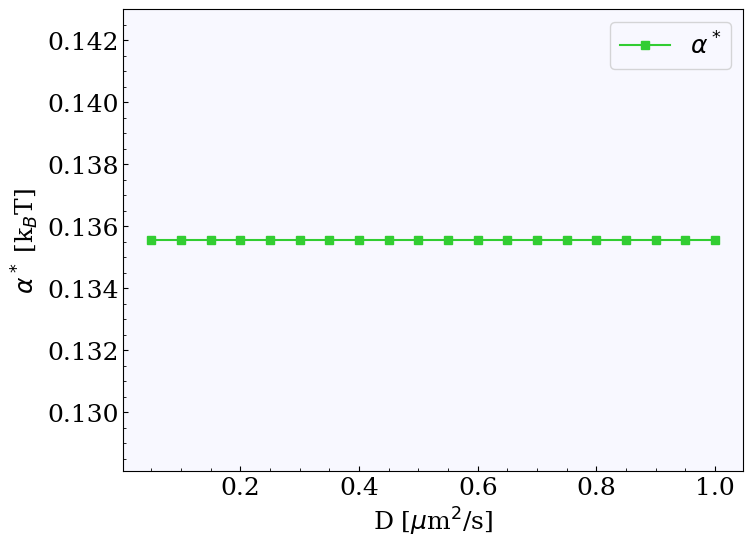

In [8]:
# Plot the optimal alpha values for the quadratic potential as a function of D0

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, optimal_alpha_quadratic_constD, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

In [89]:
def heaviside_approx(D, A, r_target, rf, rn, ndim):
    if ndim == 2: 
        T1 = (rf**2 + np.exp(-A) * (rn**2 - rf**2)) * np.log(rf/r_target) - (rf**2 - r_target**2) / 2
        T2 = rn**2 * np.log(rn/rf) - (rn**2 - rf**2) / 2
    else:
        T1 = (rf**ndim + np.exp(-A) * (rn**ndim - rf**ndim)) * (rf**(2-ndim) - r_target**(2-ndim)) / (2 - ndim) - (rf**2 - r_target**2) / 2
        T2 = rn**(ndim) * (rn**(2-ndim) - rf**(2-ndim)) / (2 - ndim) - (rn**2 - rf**2) / 2
        
    return (T1 + T2) / (D * ndim)

def strong_potential_approx(D, r_target, rf, rn, ndim):
    if ndim == 1:
        return ((rn-rf)**2 + (rf-r_target)**2) / (2 * D)
    elif ndim == 2:
        return (rf**2 * np.log(rf/r_target) + rn**2 * np.log(rn/rf) - (rn**2 - r_target**2) / 2) / (2 * D) 
    else:
        return (rf**2 / r_target * (rf - r_target) + rn**2 / rf * (rn - rf) - (rn**2 - r_target**2) / 2) / (3 * D)


In [83]:
# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx = np.zeros(N_D)
mfpt_simple_approx = np.zeros(N_D)
for i, D_i in enumerate(D_arr):
    mfpt_heaviside_approx[i] = heaviside_approx(D_i, A, r_target, rf, rn, ndim=1)
    mfpt_simple_approx[i] = strong_potential_approx(D_i, r_target, rf, rn, ndim=1)

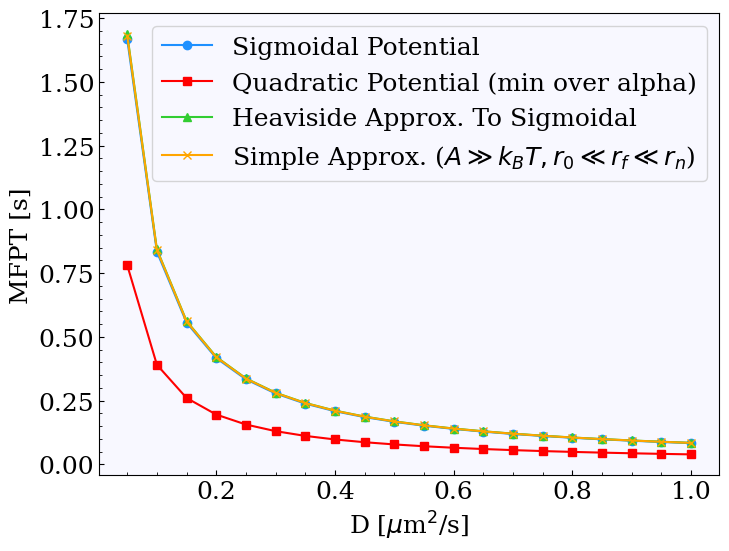

In [84]:
# Plot the results

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, mfpt_sigmoid_constD, label="Sigmoidal Potential", marker='o')
ax.plot(D_arr, min_mfpt_quadratic_constD, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(D_arr, mfpt_heaviside_approx, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.plot(D_arr, mfpt_simple_approx, label=r"Simple Approx. ($A\gg k_BT, r_0 \ll r_f \ll r_n$)", marker='x')
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel("MFPT [s]")
ax.legend()
plt.show()

## 2D

In [29]:
alpha_arr_2D = np.linspace(-2, 1.25, 200)

mfpt_sigmoid_constD_2D = np.zeros(N_D)
mfpt_quadratic_constD_2D = np.zeros((N_D, len(alpha_arr_2D)))

for i, D_i in enumerate(D_arr):
    print(f"Computing for D={D_i:.3f} ({i+1}/{N_D})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A, b, D_i, ndim=2)
    mfpt_sigmoid_constD_2D[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr_2D):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A, D_i, alpha, ndim=2)
        mfpt_quadratic_constD_2D[i, j] = quadratic_data["outer_integral"][-1]

Computing for D=0.050 (1/20)
Computing for D=0.100 (2/20)
Computing for D=0.150 (3/20)
Computing for D=0.200 (4/20)
Computing for D=0.250 (5/20)
Computing for D=0.300 (6/20)
Computing for D=0.350 (7/20)
Computing for D=0.400 (8/20)
Computing for D=0.450 (9/20)
Computing for D=0.500 (10/20)
Computing for D=0.550 (11/20)
Computing for D=0.600 (12/20)
Computing for D=0.650 (13/20)
Computing for D=0.700 (14/20)
Computing for D=0.750 (15/20)
Computing for D=0.800 (16/20)
Computing for D=0.850 (17/20)
Computing for D=0.900 (18/20)
Computing for D=0.950 (19/20)
Computing for D=1.000 (20/20)


In [98]:
# Get the mfpt for the potential, where it is monotone, i.e. where alpha is between -A/4 and A/4
mfpt_quadratic_constD_2D_monotone = np.where((alpha_arr_2D >= -A/4) & (alpha_arr_2D <= A/4), mfpt_quadratic_constD_2D, np.inf)

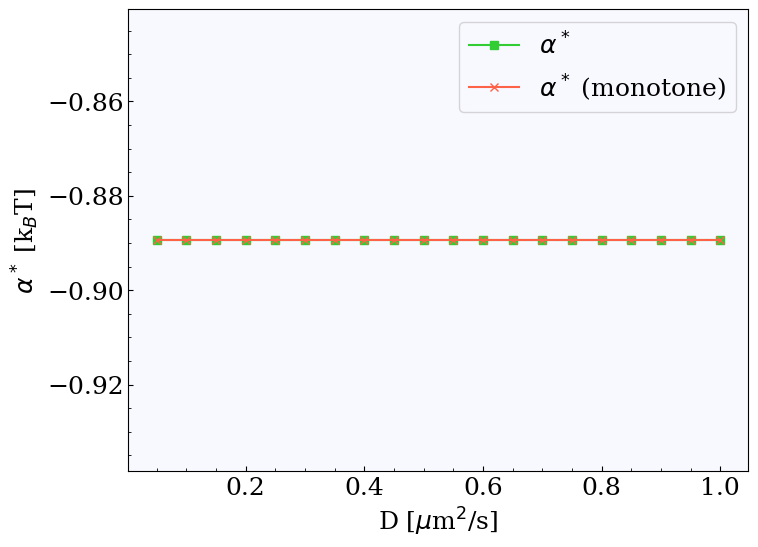

In [102]:
# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_constD_2D = np.min(mfpt_quadratic_constD_2D, axis=1)
min_mfpt_quadratic_constD_2D_monotone = np.min(mfpt_quadratic_constD_2D_monotone, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_constD_2D = alpha_arr_2D[np.argmin(mfpt_quadratic_constD_2D, axis=1)]
optimal_alpha_quadratic_constD_2D_monotone = alpha_arr_2D[np.argmin(mfpt_quadratic_constD_2D_monotone, axis=1)]

# Plot the optimal alpha values for the quadratic potential as a function of D0

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, optimal_alpha_quadratic_constD_2D, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.plot(D_arr, optimal_alpha_quadratic_constD_2D_monotone, color='tomato', marker='x', label=r"$\alpha^*$ (monotone)")
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

In [85]:
# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx_2D = np.zeros(N_D)
mfpt_simple_approx_2D = np.zeros(N_D)
for i, D_i in enumerate(D_arr):
    mfpt_heaviside_approx_2D[i] = heaviside_approx(D_i, A, r_target, rf, rn, ndim=2)
    mfpt_simple_approx_2D[i] = strong_potential_approx(D_i, r_target, rf, rn, ndim=2)

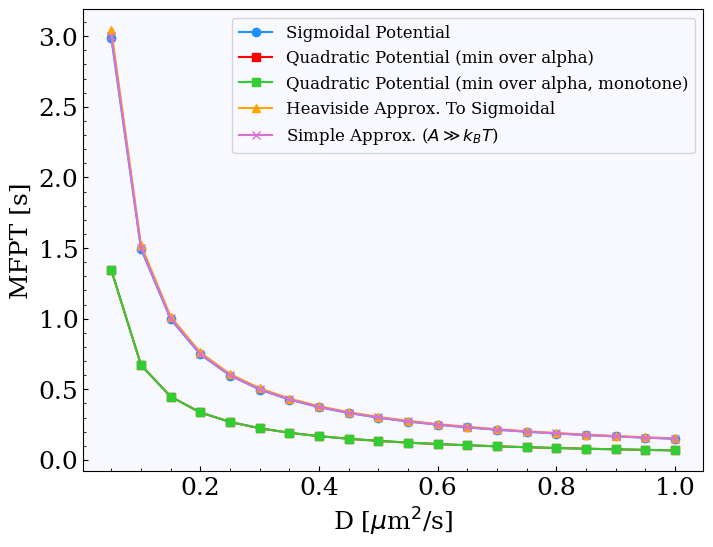

In [104]:
# Plot the results

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, mfpt_sigmoid_constD_2D, label="Sigmoidal Potential", marker='o')
ax.plot(D_arr, min_mfpt_quadratic_constD_2D, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(D_arr, min_mfpt_quadratic_constD_2D_monotone, label="Quadratic Potential (min over alpha, monotone)", marker='s')
ax.plot(D_arr, mfpt_heaviside_approx_2D, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.plot(D_arr, mfpt_simple_approx_2D, label=r"Simple Approx. ($A\gg k_BT$)", marker='x')
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel("MFPT [s]")
ax.legend(fontsize=12)
plt.show()

## 3D

In [36]:
# Repeat for 3D case - change the alpha range 

alpha_arr_3D = np.linspace(-3, 1.25, 200)

mfpt_sigmoid_constD_3D = np.zeros(N_D)
mfpt_quadratic_constD_3D = np.zeros((N_D, len(alpha_arr_3D)))

for i, D_i in enumerate(D_arr):
    print(f"Computing for D0={D_i:.3f} ({i+1}/{N_D})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A, b, D_i, ndim=3)
    mfpt_sigmoid_constD_3D[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr_3D):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A, D_i, alpha, ndim=3)
        mfpt_quadratic_constD_3D[i, j] = quadratic_data["outer_integral"][-1]

Computing for D0=0.050 (1/20)
Computing for D0=0.100 (2/20)
Computing for D0=0.150 (3/20)
Computing for D0=0.200 (4/20)
Computing for D0=0.250 (5/20)
Computing for D0=0.300 (6/20)
Computing for D0=0.350 (7/20)
Computing for D0=0.400 (8/20)
Computing for D0=0.450 (9/20)
Computing for D0=0.500 (10/20)
Computing for D0=0.550 (11/20)
Computing for D0=0.600 (12/20)
Computing for D0=0.650 (13/20)
Computing for D0=0.700 (14/20)
Computing for D0=0.750 (15/20)
Computing for D0=0.800 (16/20)
Computing for D0=0.850 (17/20)
Computing for D0=0.900 (18/20)
Computing for D0=0.950 (19/20)
Computing for D0=1.000 (20/20)


In [105]:
# Find the minimum MFPT for the quadratic case across all alpha values, where the potential is monotone, i.e. where alpha is between -A/4 and A/4
mfpt_quadratic_constD_3D_monotone = np.where((alpha_arr_3D >= -A/4) & (alpha_arr_3D <= A/4), mfpt_quadratic_constD_3D, np.inf)

# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_constD_3D = np.min(mfpt_quadratic_constD_3D, axis=1)
min_mfpt_quadratic_constD_3D_monotone = np.min(mfpt_quadratic_constD_3D_monotone, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_constD_3D = alpha_arr_3D[np.argmin(mfpt_quadratic_constD_3D, axis=1)]
optimal_alpha_quadratic_constD_3D_monotone = alpha_arr_3D[np.argmin(mfpt_quadratic_constD_3D_monotone, axis=1)]

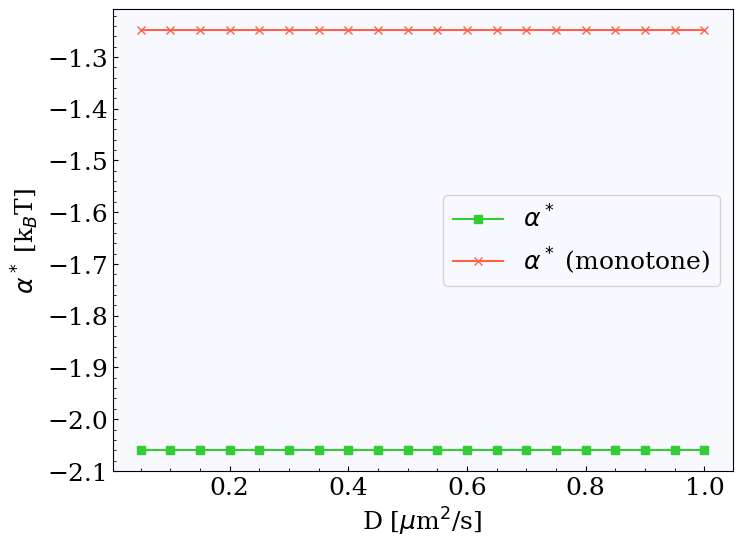

In [106]:
# Plot the optimal alpha values for the quadratic potential as a function of D0

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, optimal_alpha_quadratic_constD_3D, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.plot(D_arr, optimal_alpha_quadratic_constD_3D_monotone, color='tomato', marker='x', label=r"$\alpha^*$ (monotone)")
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

In [90]:
# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx_3D = np.zeros(N_D)
mfpt_simple_approx_3D = np.zeros(N_D)

for i, D_i in enumerate(D_arr):
    mfpt_heaviside_approx_3D[i] = heaviside_approx(D_i, A, r_target, rf, rn, ndim=3)
    mfpt_simple_approx_3D[i] = strong_potential_approx(D_i, r_target, rf, rn, ndim=3)

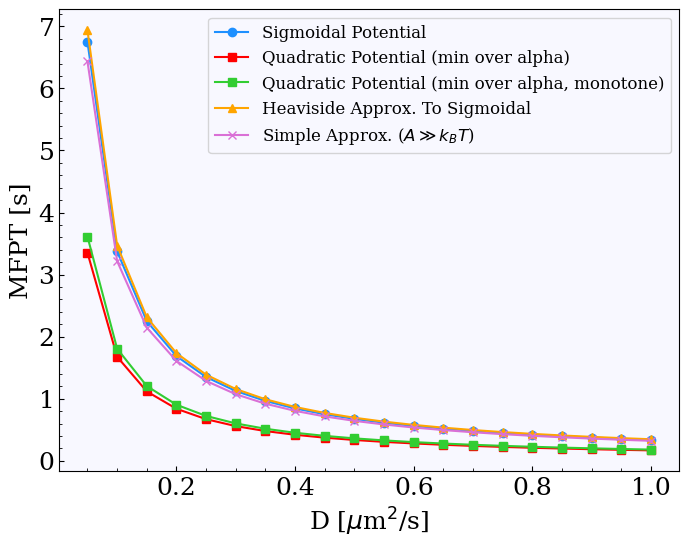

In [108]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_arr, mfpt_sigmoid_constD_3D, label="Sigmoidal Potential", marker='o')
ax.plot(D_arr, min_mfpt_quadratic_constD_3D, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(D_arr, min_mfpt_quadratic_constD_3D_monotone, label="Quadratic Potential (min over alpha, monotone)", marker='s')
ax.plot(D_arr, mfpt_heaviside_approx_3D, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.plot(D_arr, mfpt_simple_approx_3D, label=r"Simple Approx. ($A\gg k_BT$)", marker='x')
ax.set_xlabel(r"D [$\mu$m$^2$/s]")
ax.set_ylabel("MFPT [s]")
ax.legend(fontsize=12)
plt.show()

# Constant D - Test as function of A

## 1D 

In [46]:
N_A = 20
D = 0.1
A_arr = np.linspace(0.5, 10.0, N_A)
alpha_arr_A = np.linspace(-1, 1, 200)

mfpt_sigmoid_A = np.zeros(N_A)
mfpt_quadratic_A = np.zeros((N_A, len(alpha_arr_A)))

for i, A_i in enumerate(A_arr):
    print(f"Computing for A0={A_i:.3f} ({i+1}/{N_A})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A_i, b, D, ndim=1)
    mfpt_sigmoid_A[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr_A):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A_i, D, alpha, ndim=1)
        mfpt_quadratic_A[i, j] = quadratic_data["outer_integral"][-1]

Computing for A0=0.500 (1/20)
Computing for A0=1.000 (2/20)
Computing for A0=1.500 (3/20)
Computing for A0=2.000 (4/20)
Computing for A0=2.500 (5/20)
Computing for A0=3.000 (6/20)
Computing for A0=3.500 (7/20)
Computing for A0=4.000 (8/20)
Computing for A0=4.500 (9/20)
Computing for A0=5.000 (10/20)
Computing for A0=5.500 (11/20)
Computing for A0=6.000 (12/20)
Computing for A0=6.500 (13/20)
Computing for A0=7.000 (14/20)
Computing for A0=7.500 (15/20)
Computing for A0=8.000 (16/20)
Computing for A0=8.500 (17/20)
Computing for A0=9.000 (18/20)
Computing for A0=9.500 (19/20)
Computing for A0=10.000 (20/20)


In [47]:
# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_A = np.min(mfpt_quadratic_A, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_A = alpha_arr_A[np.argmin(mfpt_quadratic_A, axis=1)]

In [94]:
# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx_A = np.zeros(N_A)

for i, A_i in enumerate(A_arr):
    mfpt_heaviside_approx_A[i] = heaviside_approx(D, A_i, r_target, rf, rn, ndim=1)

mfpt_simple_approx_A = strong_potential_approx(D, r_target, rf, rn, ndim=1)

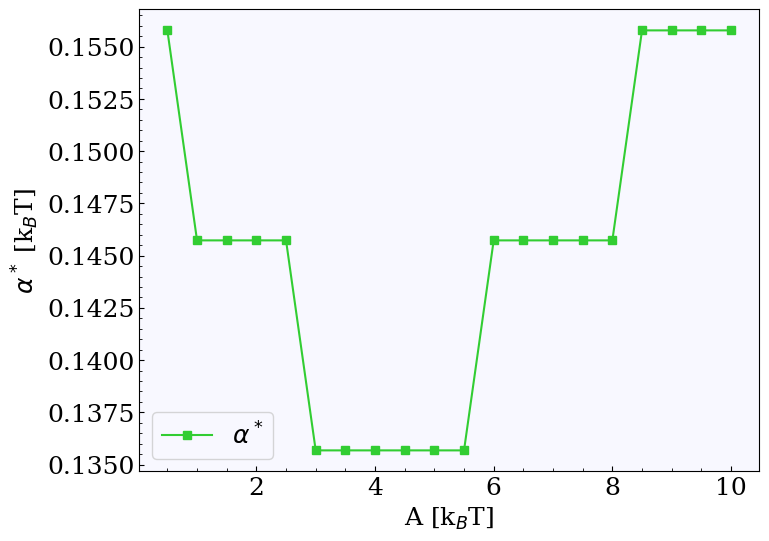

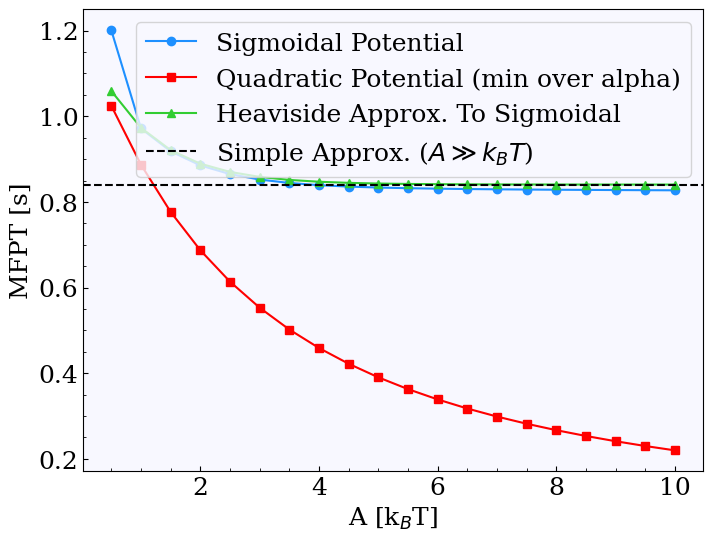

In [95]:
# Plot the optimal alpha values for the quadratic potential as a function of A

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, optimal_alpha_quadratic_A, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

# Plot the results

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, mfpt_sigmoid_A, label="Sigmoidal Potential", marker='o')
ax.plot(A_arr, min_mfpt_quadratic_A, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(A_arr, mfpt_heaviside_approx_A, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.axhline(((rn-rf)**2+(rf - r_target)**2)/(2*D), color='black', linestyle='--', label=r"Simple Approx. ($A\gg k_BT$)")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel("MFPT [s]")
ax.legend()
plt.show()

## 2D

In [111]:
alpha_arr_A_2D = np.linspace(-2.5, 2.5, 200)

mfpt_sigmoid_A_2D = np.zeros(N_A)
mfpt_quadratic_A_2D = np.zeros((N_A, len(alpha_arr_A_2D)))

for i, A_i in enumerate(A_arr):
    print(f"Computing for A0={A_i:.3f} ({i+1}/{N_A})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A_i, b, D, ndim=2)
    mfpt_sigmoid_A_2D[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr_A_2D):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A_i, D, alpha, ndim=2)
        mfpt_quadratic_A_2D[i, j] = quadratic_data["outer_integral"][-1]

Computing for A0=0.500 (1/20)
Computing for A0=1.000 (2/20)
Computing for A0=1.500 (3/20)
Computing for A0=2.000 (4/20)
Computing for A0=2.500 (5/20)
Computing for A0=3.000 (6/20)
Computing for A0=3.500 (7/20)
Computing for A0=4.000 (8/20)
Computing for A0=4.500 (9/20)
Computing for A0=5.000 (10/20)
Computing for A0=5.500 (11/20)
Computing for A0=6.000 (12/20)
Computing for A0=6.500 (13/20)
Computing for A0=7.000 (14/20)
Computing for A0=7.500 (15/20)
Computing for A0=8.000 (16/20)
Computing for A0=8.500 (17/20)
Computing for A0=9.000 (18/20)
Computing for A0=9.500 (19/20)
Computing for A0=10.000 (20/20)


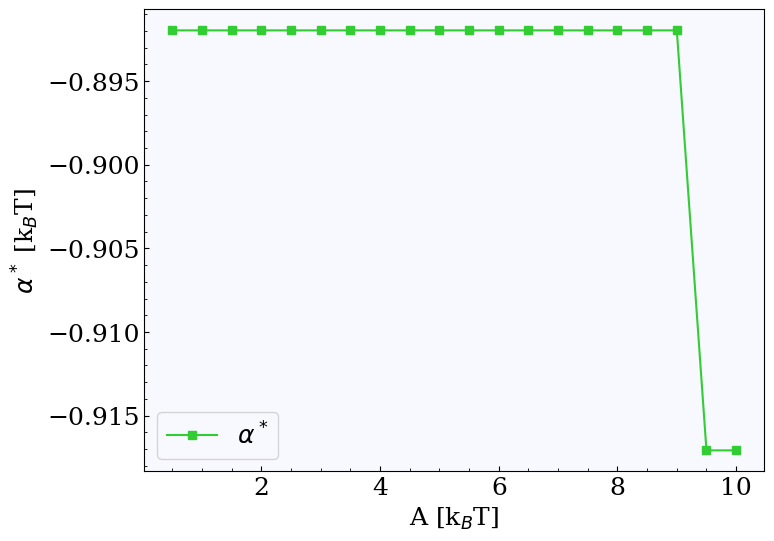

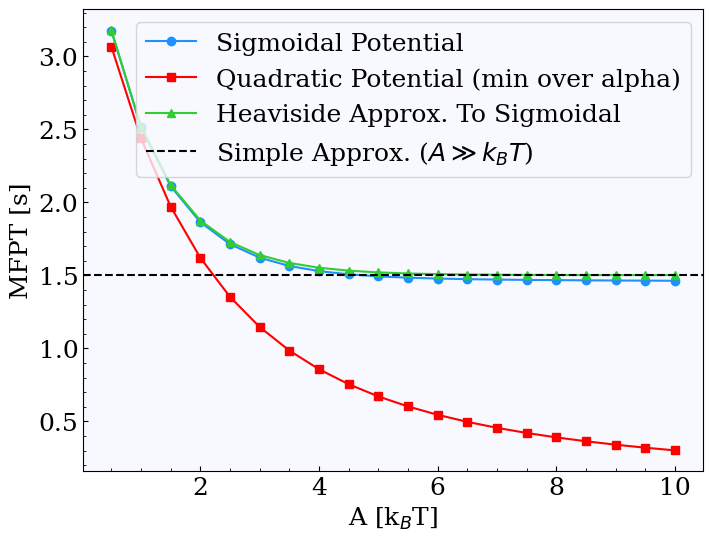

In [112]:
# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_A_2D = np.min(mfpt_quadratic_A_2D, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_A_2D = alpha_arr_A_2D[np.argmin(mfpt_quadratic_A_2D, axis=1)]

# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx_A_2D = np.zeros(N_A)
for i, A_i in enumerate(A_arr):
    mfpt_heaviside_approx_A_2D[i] = heaviside_approx(D, A_i, r_target, rf, rn, ndim=2)

mfpt_simple_approx_A_2D = strong_potential_approx(D, r_target, rf, rn, ndim=2)

# Plot the optimal alpha values for the quadratic potential as a function of A

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, optimal_alpha_quadratic_A_2D, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

# Plot the MFPT results

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, mfpt_sigmoid_A_2D, label="Sigmoidal Potential", marker='o')
ax.plot(A_arr, min_mfpt_quadratic_A_2D, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(A_arr, mfpt_heaviside_approx_A_2D, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.axhline(mfpt_simple_approx_A_2D, color='black', linestyle='--', label=r"Simple Approx. ($A\gg k_BT$)")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel("MFPT [s]")
ax.legend()
plt.show()


## 3D

In [113]:
alpha_arr_A_3D = np.linspace(-4, 2.5, 200)

mfpt_sigmoid_A_3D = np.zeros(N_A)
mfpt_quadratic_A_3D = np.zeros((N_A, len(alpha_arr_A_3D)))

for i, A_i in enumerate(A_arr):
    print(f"Computing for A0={A_i:.3f} ({i+1}/{N_A})")
    # Sigmoidal potential with constant diffusion
    F_sigmoid, sigmoid_data = compute_for_sigmoidal_constantD(r_target, rf, rn, A_i, b, D, ndim=3)
    mfpt_sigmoid_A_3D[i] = sigmoid_data["outer_integral"][-1]

    # Quadratic potential with constant diffusion
    for j, alpha in enumerate(alpha_arr_A_3D):
        F_quadratic, quadratic_data = compute_for_constant_diffusion(r_target, rn, A_i, D, alpha, ndim=3)
        mfpt_quadratic_A_3D[i, j] = quadratic_data["outer_integral"][-1]

Computing for A0=0.500 (1/20)
Computing for A0=1.000 (2/20)
Computing for A0=1.500 (3/20)
Computing for A0=2.000 (4/20)
Computing for A0=2.500 (5/20)
Computing for A0=3.000 (6/20)
Computing for A0=3.500 (7/20)
Computing for A0=4.000 (8/20)
Computing for A0=4.500 (9/20)
Computing for A0=5.000 (10/20)
Computing for A0=5.500 (11/20)
Computing for A0=6.000 (12/20)
Computing for A0=6.500 (13/20)
Computing for A0=7.000 (14/20)
Computing for A0=7.500 (15/20)
Computing for A0=8.000 (16/20)
Computing for A0=8.500 (17/20)
Computing for A0=9.000 (18/20)
Computing for A0=9.500 (19/20)
Computing for A0=10.000 (20/20)


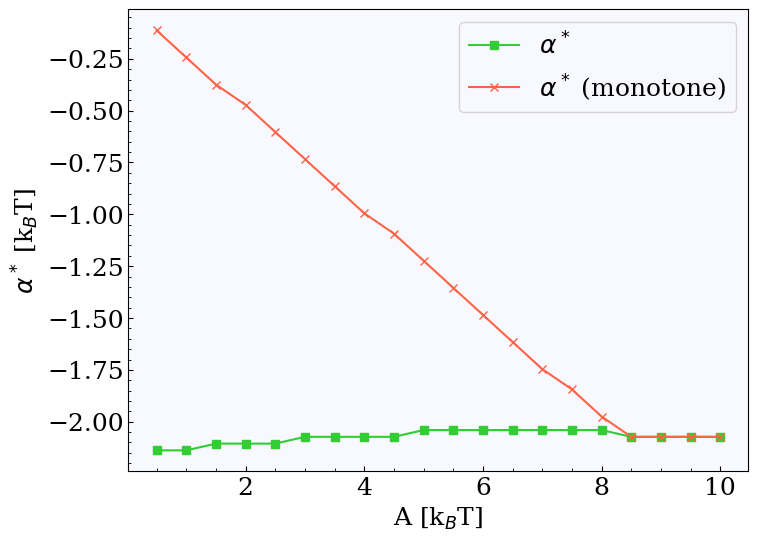

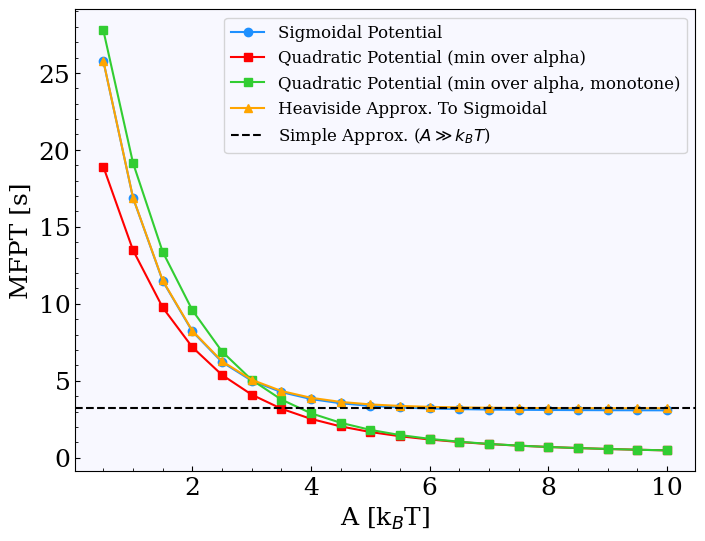

In [115]:
# Find the minimum MFPT for the quadratic case across all alpha values, where the potential is monotone, i.e. where alpha is between -A/4 and A/4
# Need to loop over A values, since the monotonicity condition depends on A
mfpt_quadratic_A_3D_monotone = np.zeros_like(mfpt_quadratic_A_3D)
for i, A_i in enumerate(A_arr):
    monotone_mask = (alpha_arr_A_3D >= -A_i/4) & (alpha_arr_A_3D <= A_i/4)
    mfpt_quadratic_A_3D_monotone[i, ~monotone_mask] = np.inf
    mfpt_quadratic_A_3D_monotone[i, monotone_mask] = mfpt_quadratic_A_3D[i, monotone_mask]

# Find the minimum MFPT for the quadratic case across all alpha values
min_mfpt_quadratic_A_3D = np.min(mfpt_quadratic_A_3D, axis=1)
min_mfpt_quadratic_A_3D_monotone = np.min(mfpt_quadratic_A_3D_monotone, axis=1)

# Find the correspinding alpha values that minimize the MFPT for the quadratic case
optimal_alpha_quadratic_A_3D = alpha_arr_A_3D[np.argmin(mfpt_quadratic_A_3D, axis=1)]
optimal_alpha_quadratic_A_3D_monotone = alpha_arr_A_3D[np.argmin(mfpt_quadratic_A_3D_monotone, axis=1)]

# Calculate the Heaviside approximation for the sigmoidal potential with constant diffusion
mfpt_heaviside_approx_A_3D = np.zeros(N_A)
for i, A_i in enumerate(A_arr):
    mfpt_heaviside_approx_A_3D[i] = heaviside_approx(D, A_i, r_target, rf, rn, ndim=3)

mfpt_simple_approx_A_3D = strong_potential_approx(D, r_target, rf, rn, ndim=3)

# Plot the optimal alpha values for the quadratic potential as a function of A

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, optimal_alpha_quadratic_A_3D, color='limegreen', marker='s', label=r"$\alpha^*$")
ax.plot(A_arr, optimal_alpha_quadratic_A_3D_monotone, color='tomato', marker='x', label=r"$\alpha^*$ (monotone)")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel(r"$\alpha^*$ [k$_B$T]")
ax.legend()
plt.show()

# Plot the MFPT results

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_arr, mfpt_sigmoid_A_3D, label="Sigmoidal Potential", marker='o')
ax.plot(A_arr, min_mfpt_quadratic_A_3D, label="Quadratic Potential (min over alpha)", marker='s')
ax.plot(A_arr, min_mfpt_quadratic_A_3D_monotone, label="Quadratic Potential (min over alpha, monotone)", marker='s')
ax.plot(A_arr, mfpt_heaviside_approx_A_3D, label="Heaviside Approx. To Sigmoidal", marker='^')
ax.axhline(mfpt_simple_approx_A_3D, color='black', linestyle='--', label=r"Simple Approx. ($A\gg k_BT$)")
ax.set_xlabel(r"A [k$_B$T]")
ax.set_ylabel("MFPT [s]")
ax.legend(fontsize=12)
plt.show()